# Notebook 3b — Efecto causal de la cochera incluida (tratamiento binario)

## Protocolo (fijado antes de estimar)

| Elemento | Decisión |
|---|---|
| Población | Avisos de la muestra auditada con geocodificación **ROOFTOP** (notebook 2) y tratamiento definido (notebook 2b). |
| Tratamiento D | **Cochera incluida en el alquiler** (1) frente a **sin cochera** (0). Se excluyen los avisos con cochera de costo extra y los ambiguos. |
| Resultado Y | log(precio mensual de oferta). Efecto en % = 100·(e^θ − 1). |
| Estimando | **ATE en la población con soporte común**: avisos con propensión P(D=1\|X) entre 0.05 y 0.95. También se reporta el ATE sin recorte. |
| Conjunto de ajuste | log(área), dormitorios, **baños**, antigüedad (+ indicador de faltante), latitud, longitud, días publicado, distrito y tipo de geocodificación. |
| Estimador | DML interactivo (IRM/AIPW): clasificador de *gradient boosting* para la propensión y regresores por brazo para E[Y\|D,X]; 5 folds agrupados por edificio; 10 repeticiones. |
| Inferencia | EE agrupado por edificio (principal) y por bloque de 1 km. |
| Diagnósticos | Propensión fuera de fold (log-loss, Brier, AUC), histograma por brazo, % fuera de soporte, balance (SMD) antes y después de ponderar. |
| Sensibilidad | Cota de sesgo por confusor omitido para el IRM, valor de robustez y benchmarks con confusores observados. |
| Heterogeneidad | GATE por clase de distrito y por quintil de área. |

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from causal_utils import *

sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
ORIGEN = "notebook3b_efecto_cochera.ipynb"
base = pd.read_csv("../csv/data_causal_base.csv")
dd = agregar_cochera(muestra(base))
print("Muestra ROOFTOP:", len(dd), "| sin dato de cochera:", int(dd["tipo_cochera"].isna().sum()))
print(dd["tipo_cochera"].value_counts().to_dict())
d = dd.dropna(subset=["T_cochera"]).reset_index(drop=True)
d["D"] = d["T_cochera"].astype(int)

NUM_C = ["area_log", "dormitorios", "banos", "antig", "antig_na", "latitud", "longitud", "dias_pub"]
X = matriz(d, NUM_C, CAT); Y = d["Y"].values; D = d["D"].values
G = d["edificio_id"].values
CL = {"edificio": d["edificio_id"].values, "celda_1km": d["celda_1km"].values}
REF = float(d["precio"].median())
print(f"N analítico = {len(d)} | con cochera incluida = {D.sum()} ({100 * D.mean():.1f} %) | controles = {X.shape[1]} | alquiler de referencia S/ {REF:,.0f}")

Muestra ROOFTOP: 2220 | sin dato de cochera: 0
{'incluida': 1095, 'sin_mencion': 659, 'no_tiene': 297, 'costo_extra': 150, 'ambigua': 19}
N analítico = 2051 | con cochera incluida = 1095 (53.4 %) | controles = 23 | alquiler de referencia S/ 2,650


## 1. DAG para la cochera

La ubicación, la antigüedad y el tamaño del edificio y del departamento se fijan antes de decidir si la unidad tiene cochera, y afectan
también al precio: son **confusores**. Los **baños** ahora entran como control: no son consecuencia de la cochera, pero ambos reflejan el
estándar del edificio. El precio por m² sigue siendo inadmisible. El confusor no observado principal es la **calidad del edificio**
(acabados, amenidades, seguridad).

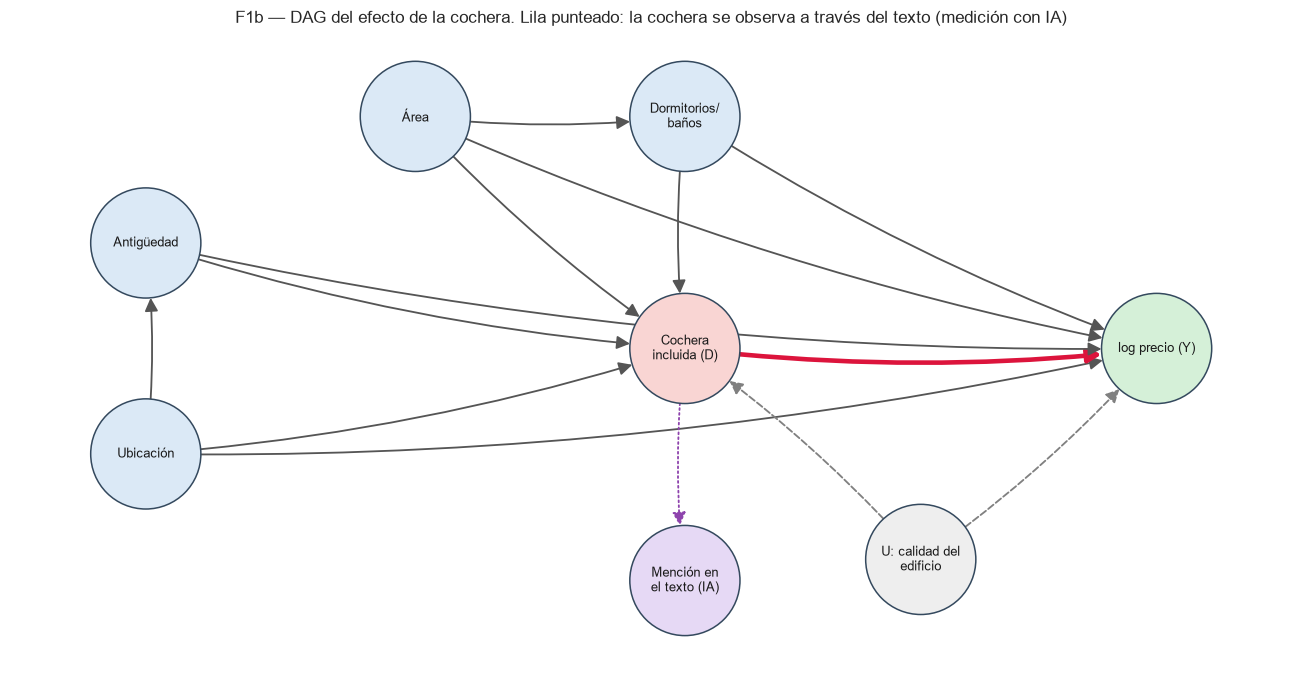

In [2]:
G2 = nx.DiGraph()
for c in ["Ubicación", "Antigüedad", "Área", "Dormitorios/\nbaños"]:
    G2.add_edge(c, "Cochera\nincluida (D)"); G2.add_edge(c, "log precio (Y)")
G2.add_edge("Ubicación", "Antigüedad"); G2.add_edge("Área", "Dormitorios/\nbaños")
G2.add_edge("Cochera\nincluida (D)", "log precio (Y)", color="crimson", w=3)
for v in ["Cochera\nincluida (D)", "log precio (Y)"]:
    G2.add_edge("U: calidad del\nedificio", v, color="gray", style="dashed")
G2.add_edge("Cochera\nincluida (D)", "Mención en\nel texto (IA)", color="#8e44ad", style="dotted")
pos = {"Ubicación": (0, 0), "Antigüedad": (0, 2), "Área": (1.6, 3.2), "Dormitorios/\nbaños": (3.2, 3.2),
       "Cochera\nincluida (D)": (3.2, 1.0), "log precio (Y)": (6, 1.0), "U: calidad del\nedificio": (4.6, -1.0),
       "Mención en\nel texto (IA)": (3.2, -1.2)}
col = {"Cochera\nincluida (D)": "#f9d5d3", "log precio (Y)": "#d5f0d8", "U: calidad del\nedificio": "#eeeeee", "Mención en\nel texto (IA)": "#e6d9f5"}
fig, ax = plt.subplots(figsize=(12, 6.5))
nx.draw_networkx_nodes(G2, pos, node_size=5200, node_color=[col.get(n, "#dbe9f6") for n in G2.nodes], edgecolors="#34495e", ax=ax)
nx.draw_networkx_labels(G2, pos, font_size=8.5, ax=ax)
for u, v, a in G2.edges(data=True):
    nx.draw_networkx_edges(G2, pos, edgelist=[(u, v)], ax=ax, arrows=True, arrowsize=18, node_size=5200, width=a.get("w", 1.2),
                           edge_color=a.get("color", "#555"), style=a.get("style", "solid"), connectionstyle="arc3,rad=0.06")
ax.set_xlim(-0.8, 6.8); ax.set_ylim(-2.2, 4.0); ax.axis("off")
ax.set_title("F1b — DAG del efecto de la cochera. Lila punteado: la cochera se observa a través del texto (medición con IA)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "F1b_dag_cochera.png", bbox_inches="tight"); plt.show()

## 2. Estimación con DML-IRM y diagnóstico de soporte común (R2)

,diagnóstico,valor
0,AUC de la propensión (fuera de fold),0.824
1,Log-loss,0.516
2,Brier,0.171
3,"R² de E[Y|D,X] (fuera de fold)",0.824
4,Propensión mínima / máxima,0.004 / 0.992
5,"% fuera de [0.05, 0.95]",5.0 %
6,N en soporte común,"1,949"
7,Tratados / controles en soporte común,"1,046 / 903"


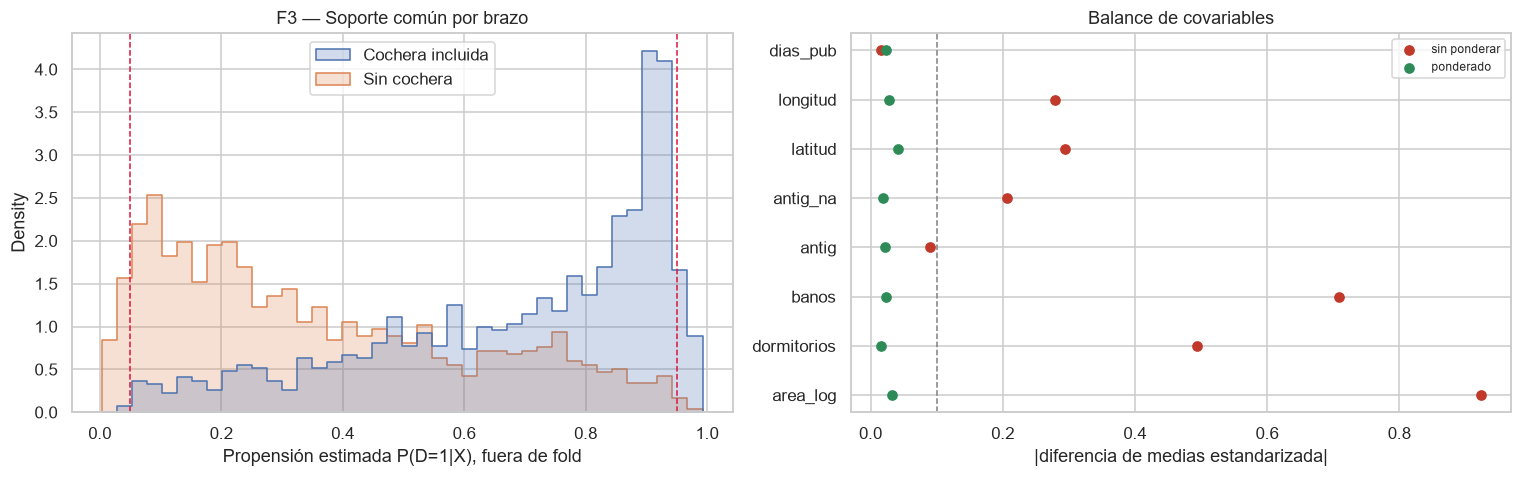

,variable,SMD sin ponderar,"SMD ponderado (IPW, soporte común)"
0,area_log,0.924,-0.033
1,dormitorios,0.494,-0.016
2,banos,0.709,-0.023
3,antig,0.090,-0.021
4,antig_na,-0.207,-0.019
5,latitud,-0.295,0.042
6,longitud,0.279,0.028
7,dias_pub,-0.016,-0.023


In [3]:
irm = dml_irm(Y, D, X.values, G, CL, n_rep=10)
dg = irm["diag"]; m = dg["m"]
fuera = (m < 0.05) | (m > 0.95)
r2 = pd.DataFrame({
  "diagnóstico": ["AUC de la propensión (fuera de fold)", "Log-loss", "Brier", "R² de E[Y|D,X] (fuera de fold)",
                  "Propensión mínima / máxima", "% fuera de [0.05, 0.95]", "N en soporte común", "Tratados / controles en soporte común"],
  "valor": [f"{dg['auc']:.3f}", f"{dg['logloss']:.3f}", f"{dg['brier']:.3f}", f"{dg['r2_y']:.3f}", f"{m.min():.3f} / {m.max():.3f}",
            f"{100 * fuera.mean():.1f} %", f"{irm['recortada']['n']:,}",
            f"{int(D[~fuera].sum()):,} / {int((1 - D[~fuera]).sum()):,}"]})
guardar_tabla(r2, "R2_soporte", origen=ORIGEN)
display(r2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(x=m, hue=np.where(D == 1, "Cochera incluida", "Sin cochera"), bins=40, stat="density", common_norm=False,
             element="step", ax=ax[0])
for v in (0.05, 0.95): ax[0].axvline(v, color="crimson", ls="--", lw=1)
ax[0].set_xlabel("Propensión estimada P(D=1|X), fuera de fold"); ax[0].set_title("F3 — Soporte común por brazo")
mc = np.clip(m, 0.01, 0.99); w = np.where(D == 1, 1 / mc, 1 / (1 - mc))
cols_b = ["area_log", "dormitorios", "banos", "antig", "antig_na", "latitud", "longitud", "dias_pub"]
b0 = balance(d[cols_b], D); b1 = balance(d.loc[~fuera, cols_b], D[~fuera], w[~fuera])
bal = b0.rename(columns={"SMD": "SMD sin ponderar"}).merge(b1.rename(columns={"SMD": "SMD ponderado (IPW, soporte común)"}), on="variable")
guardar_tabla(bal, "R2_balance", origen=ORIGEN)
ax[1].scatter(bal.iloc[:, 1].abs(), range(len(bal)), label="sin ponderar", color="#c0392b")
ax[1].scatter(bal.iloc[:, 2].abs(), range(len(bal)), label="ponderado", color="#2e8b57")
ax[1].axvline(0.1, color="gray", ls="--", lw=1); ax[1].set_yticks(range(len(bal))); ax[1].set_yticklabels(bal["variable"])
ax[1].set_xlabel("|diferencia de medias estandarizada|"); ax[1].set_title("Balance de covariables"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "F3_soporte_cochera.png", bbox_inches="tight"); plt.show()
bal.round(3)

## 3. Estimación primaria (R3)

In [4]:
b0_, s0_ = ols_efecto(Y, D, None, CL["edificio"])
b1_, s1_ = ols_efecto(Y, D, X.values, CL["edificio"])
plr = dml_plr(Y, D, X.values, G, CL, n_rep=5)
filas = [("Diferencia sin ajustar (OLS)", b0_, s0_, len(d)), ("Hedónico OLS", b1_, s1_, len(d)),
         ("DML parcialmente lineal (PLR)", plr["theta"], plr["se"]["edificio"], len(d)),
         ("DML-IRM, muestra completa", irm["completa"]["theta"], irm["completa"]["se"]["edificio"], irm["completa"]["n"]),
         ("DML-IRM, soporte común (principal)", irm["recortada"]["theta"], irm["recortada"]["se"]["edificio"], irm["recortada"]["n"])]
r3 = pd.DataFrame(filas, columns=["estimador", "theta", "EE (cluster edificio)", "N"])
r3["IC95 inf"] = r3["theta"] - 1.96 * r3["EE (cluster edificio)"]; r3["IC95 sup"] = r3["theta"] + 1.96 * r3["EE (cluster edificio)"]
r3["% efecto"] = pct(r3["theta"]); r3["% IC inf"] = pct(r3["IC95 inf"]); r3["% IC sup"] = pct(r3["IC95 sup"])
r3["S/ al mes (ref.)"] = REF * (np.exp(r3["theta"]) - 1)
guardar_tabla(r3, "R3c_principal", origen=ORIGEN)
th, se = irm["recortada"]["theta"], irm["recortada"]["se"]["edificio"]
print(f"EE alternativos (soporte común): iid {irm['recortada']['se']['iid']:.4f} | celda 1 km {irm['recortada']['se']['celda_1km']:.4f}")
print("Repeticiones del cross-fitting:", np.round(irm["recortada"]["thetas"], 4))
r3.round(4)

EE alternativos (soporte común): iid 0.0181 | celda 1 km 0.0218
Repeticiones del cross-fitting: [0.0716 0.0732 0.0813 0.0668 0.0844 0.0896 0.0707 0.0833 0.0711 0.0655]


,estimador,theta,EE (cluster edificio),N,IC95 inf,IC95 sup,% efecto,% IC inf,% IC sup,S/ al mes (ref.)
0,Diferencia sin ajustar (OLS),0.4883,0.0197,2051,0.4496,0.5270,62.9565,56.7731,69.3837,1668.3468
1,Hedónico OLS,0.0748,0.0133,2051,0.0487,0.1009,7.7684,4.9901,10.6202,205.8625
2,DML parcialmente lineal (PLR),0.0683,0.0119,2051,0.0449,0.0917,7.0713,4.5967,9.6044,187.3890
3,"DML-IRM, muestra completa",0.0425,0.0356,2051,-0.0272,0.1122,4.3422,-2.6839,11.8756,115.0681
4,"DML-IRM, soporte común (principal)",0.0724,0.0184,1949,0.0364,0.1084,7.5080,3.7100,11.4451,198.9609


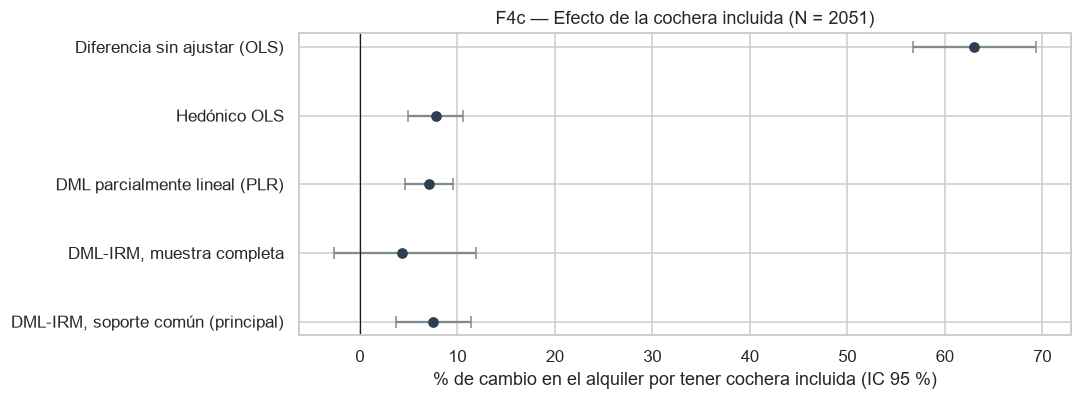

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.errorbar(r3["% efecto"], range(len(r3)), xerr=[r3["% efecto"] - r3["% IC inf"], r3["% IC sup"] - r3["% efecto"]],
            fmt="o", capsize=4, color="#2c3e50", ecolor="#7f8c8d")
ax.set_yticks(range(len(r3))); ax.set_yticklabels(r3["estimador"]); ax.invert_yaxis(); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("% de cambio en el alquiler por tener cochera incluida (IC 95 %)")
ax.set_title(f"F4c — Efecto de la cochera incluida (N = {len(d)})")
plt.tight_layout(); plt.savefig(FIG / "F4c_estimadores_cochera.png", bbox_inches="tight"); plt.show()

## 4. Grilla de especificaciones (R4)

In [6]:
def correr(nombre, tipo, dd_=None, num=NUM_C, cat=CAT, extra=(), trat="T_cochera", folds_col="edificio_id", n_rep=3):
    q = (d if dd_ is None else dd_).dropna(subset=[trat]).reset_index(drop=True)
    Xs = matriz(q, num, cat, extra).values
    r = dml_irm(q["Y"].values, q[trat].astype(int).values, Xs, q[folds_col].values, {"cl": q[folds_col].values}, n_rep=n_rep)["recortada"]
    t, s = r["theta"], r["se"]["cl"]
    return {"código": nombre.split(" ")[0], "especificación": nombre[len(nombre.split(" ")[0]) + 1:], "tipo": tipo,
            "N": r["n"], "theta": t, "EE": s, "IC95 inf": t - 1.96 * s, "IC95 sup": t + 1.96 * s, "% efecto": pct(t)}

sinv = lambda *v: [c for c in NUM_C if c not in v]
d_extra = dd.assign(T_extra=np.select([dd["tipo_cochera"].isin(["incluida", "costo_extra"]),
                                       dd["tipo_cochera"].isin(["no_tiene", "sin_mencion"])], [1, 0], np.nan))
grid = [
  correr("C1 Principal", "válida"),
  correr("C2 Sin área", "omite confusor", num=sinv("area_log")),
  correr("C3 Sin ubicación (distrito, lat, lon)", "omite confusor", num=sinv("latitud", "longitud"), cat=["tipo_ubic"]),
  correr("C4 Sin baños ni dormitorios", "omite confusor", num=sinv("banos", "dormitorios")),
  correr("C5 Sin antigüedad", "omite confusor", num=sinv("antig", "antig_na")),
  correr("C6 + precio/m² (descendiente de Y)", "control inadmisible", extra=["precioxm2"]),
  correr("C7 Tratamiento estricto (incluida explícita)", "medición", trat="T_cochera_estricta", dd_=dd),
  correr("C8 Cochera con costo extra también como D=1", "medición", trat="T_extra", dd_=d_extra),
  correr("C9 + indicador de descripción cortada", "medición", extra=["cortada"]),
  correr("P1 Folds y EE por bloque de 1 km", "partición", folds_col="celda_1km"),
]
r4 = pd.DataFrame(grid)
guardar_tabla(r4, "R4c_especificaciones", origen=ORIGEN)
r4.round(4)

,código,especificación,tipo,N,theta,EE,IC95 inf,IC95 sup,% efecto
0,C1,Principal,válida,1931,0.0732,0.0166,0.0407,0.1057,7.5921
1,C2,Sin área,omite confusor,1972,0.1081,0.0272,0.0548,0.1614,11.4163
2,C3,"Sin ubicación (distrito, lat, lon)",omite confusor,1975,0.1961,0.0201,0.1567,0.2356,21.6695
3,C4,Sin baños ni dormitorios,omite confusor,1941,0.0868,0.0183,0.0509,0.1226,9.0651
4,C5,Sin antigüedad,omite confusor,1930,0.0775,0.0173,0.0436,0.1115,8.0606
5,C6,+ precio/m² (descendiente de Y),control inadmisible,1820,-0.0046,0.0080,-0.0202,0.0111,-0.4565
6,C7,Tratamiento estricto (incluida explícita),medición,547,0.0764,0.0342,0.0095,0.1434,7.9445
7,C8,Cochera con costo extra también como D=1,medición,2113,0.0515,0.0156,0.0210,0.0820,5.2869
8,C9,+ indicador de descripción cortada,medición,1926,0.0717,0.0181,0.0363,0.1071,7.4372
9,P1,Folds y EE por bloque de 1 km,partición,1953,0.0738,0.0204,0.0338,0.1138,7.6586


## 5. Robustez a confusores no observados (R5)

Para el IRM, la cota de sesgo de Chernozhukov, Cinelli, Newey, Sharma y Syrgkanis usa la varianza del error del resultado (σ²) y el segundo
momento del representante de Riesz (ν² = E[α²], con α = D/m − (1−D)/(1−m)). Los benchmarks miden cuánto cambiarían σ² y ν² si se omitiera un
bloque de confusores observados.

In [7]:
largo = dml_irm(Y, D, X.values, G, CL, n_rep=1)["recortada"]
s2, nu2 = largo["sigma2"], largo["nu2"]
bloques = {"área": dict(num=sinv("area_log")), "ubicación": dict(num=sinv("latitud", "longitud"), cat=["tipo_ubic"]),
           "baños y dormitorios": dict(num=sinv("banos", "dormitorios")), "antigüedad": dict(num=sinv("antig", "antig_na"))}
bench = {}
for k, kw in bloques.items():
    corto = dml_irm(Y, D, matriz(d, kw.get("num", NUM_C), kw.get("cat", CAT)).values, G, CL, n_rep=1)["recortada"]
    bench[k] = benchmark_irm(largo, corto)
rv = valor_robustez(th, s2, 1 / nu2); rva = valor_robustez(th, s2, 1 / nu2, se=se, z=1.96)
filas = [{"referencia": "Estimación DML-IRM principal", "R2 con D": np.nan, "R2 con Y": np.nan, "theta ajustado": th,
          "IC95 inf ajustado": th - 1.96 * se, "% ajustado": pct(th)}]
for k, (cd, cy) in bench.items():
    for mult in (1, 2):
        b = sesgo_max(mult * cy, mult * cd, s2, 1 / nu2)
        filas.append({"referencia": f"U {mult}× tan fuerte como {k}", "R2 con D": mult * cd, "R2 con Y": mult * cy,
                      "theta ajustado": th - b, "IC95 inf ajustado": th - b - 1.96 * se, "% ajustado": pct(th - b)})
r5 = pd.DataFrame(filas); guardar_tabla(r5, "R5c_sensibilidad", origen=ORIGEN)
r5b = pd.DataFrame({"indicador": ["RV (θ → 0)", "RV_α (límite inferior IC → 0)"], "valor": [rv, rva]})
guardar_tabla(r5b, "R5c_robustez", origen=ORIGEN)
display(r5b.round(4)); r5.round(4)

,indicador,valor
0,RV (θ → 0),0.1052
1,RV_α (límite inferior IC → 0),0.0544


,referencia,R2 con D,R2 con Y,theta ajustado,IC95 inf ajustado,% ajustado
0,Estimación DML-IRM principal,NaN,NaN,0.0724,0.0364,7.5080
1,U 1× tan fuerte como área,0.0000,0.4459,0.0724,0.0364,7.5080
2,U 2× tan fuerte como área,0.0000,0.8918,0.0724,0.0364,7.5080
3,U 1× tan fuerte como ubicación,0.1204,0.3645,-0.0730,-0.1089,-7.0380
4,U 2× tan fuerte como ubicación,0.2408,0.7290,-0.2406,-0.2765,-21.3812
5,U 1× tan fuerte como baños y dormitorios,0.0000,0.0230,0.0724,0.0364,7.5080
6,U 2× tan fuerte como baños y dormitorios,0.0000,0.0460,0.0724,0.0364,7.5080
7,U 1× tan fuerte como antigüedad,0.1206,0.0804,0.0041,-0.0319,0.4082
8,U 2× tan fuerte como antigüedad,0.2412,0.1607,-0.0747,-0.1107,-7.1984


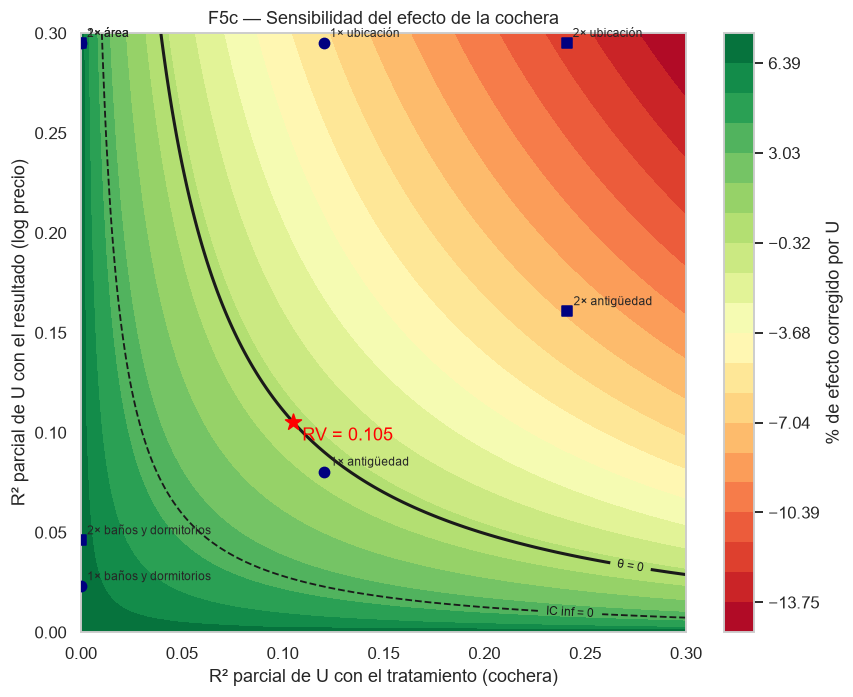

In [8]:
g = np.linspace(0, 0.30, 121); R2D, R2Y = np.meshgrid(g, g)
aj = th - sesgo_max(R2Y, R2D, s2, 1 / nu2)
fig, ax = plt.subplots(figsize=(8, 6.5))
cs = ax.contourf(R2D, R2Y, pct(aj), levels=np.linspace(pct(aj).min(), pct(th), 21), cmap="RdYlGn")
plt.colorbar(cs, label="% de efecto corregido por U")
c0 = ax.contour(R2D, R2Y, aj, levels=[0], colors="k", linewidths=2); c1 = ax.contour(R2D, R2Y, aj - 1.96 * se, levels=[0], colors="k", linewidths=1.2, linestyles="--")
ax.clabel(c0, fmt={0: "θ = 0"}, fontsize=8); ax.clabel(c1, fmt={0: "IC inf = 0"}, fontsize=8)
for k, (cd, cy) in bench.items():
    for mult, mk in ((1, "o"), (2, "s")):
        x_, y_ = min(mult * cd, .295), min(mult * cy, .295)
        ax.scatter(x_, y_, c="navy", marker=mk, s=45, zorder=3); ax.annotate(f"{mult}× {k}", (x_, y_), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.scatter(rv, rv, c="red", marker="*", s=120, zorder=4); ax.annotate(f"RV = {rv:.3f}", (rv, rv), xytext=(6, -12), textcoords="offset points", color="red")
ax.set_xlabel("R² parcial de U con el tratamiento (cochera)"); ax.set_ylabel("R² parcial de U con el resultado (log precio)")
ax.set_title("F5c — Sensibilidad del efecto de la cochera"); plt.tight_layout(); plt.savefig(FIG / "F5c_sensibilidad_cochera.png", bbox_inches="tight"); plt.show()

## 6. Heterogeneidad preespecificada (R7) y dependencia espacial

,segmentación,grupo,n,theta,ee,ic_inf,ic_sup,ic_sim_inf,ic_sim_sup,% efecto,Wald (igualdad),p-valor Wald
0,clase de distrito,clase1,876,0.0149,0.0192,-0.0228,0.0525,-0.0311,0.0609,1.4989,18.2676,0.0001
1,clase de distrito,clase2,605,0.0976,0.0308,0.0373,0.1579,0.0239,0.1713,10.2503,18.2676,0.0001
2,clase de distrito,clase3,468,0.1638,0.0307,0.1036,0.2240,0.0903,0.2373,17.7992,18.2676,0.0001
3,quintil de área,Q1 (25-55 m2),420,0.1126,0.0258,0.0619,0.1632,0.0460,0.1791,11.9151,4.4550,0.3479
4,quintil de área,Q2 (56-70 m2),385,0.0964,0.0242,0.0490,0.1438,0.0341,0.1587,10.1193,4.4550,0.3479
5,quintil de área,Q3 (70-89 m2),374,0.0410,0.0300,-0.0179,0.0998,-0.0364,0.1183,4.1823,4.4550,0.3479
6,quintil de área,Q4 (90-116 m2),380,0.0528,0.0327,-0.0114,0.1170,-0.0316,0.1371,5.4198,4.4550,0.3479
7,quintil de área,Q5 (117-440 m2),390,0.0743,0.0481,-0.0200,0.1685,-0.0496,0.1982,7.7092,4.4550,0.3479


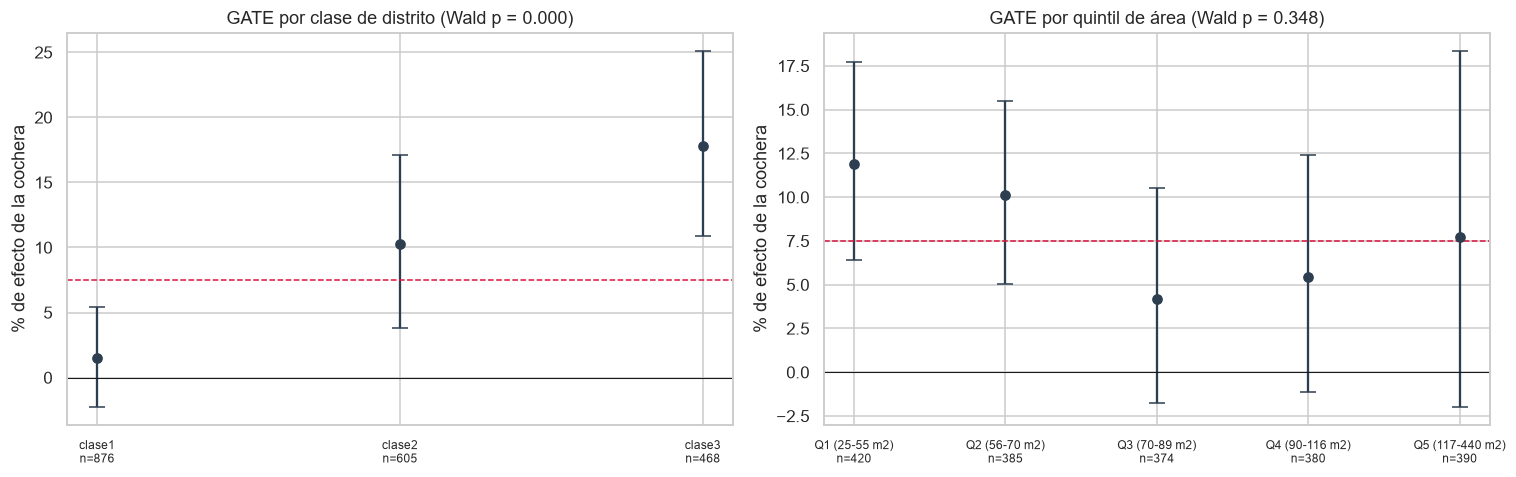

I de Moran del residuo del resultado: 0.0188 (p = 0.025) | EE iid 0.0181, edificio 0.0184, celda 0.0218


In [9]:
msk = irm["recortada"]["mask"]; phi = irm["recortada"]["phi"]; dm = d[msk].reset_index(drop=True)
dm["quintil_area"] = pd.qcut(dm["area"], 5, labels=[f"Q{i}" for i in range(1, 6)])
rq = dm.groupby("quintil_area", observed=True)["area"].agg(["min", "max"])
tabs = []
for seg, nom in [("distrito_clase", "clase de distrito"), ("quintil_area", "quintil de área")]:
    tb, w_, pw = gate_irm(phi, dm[seg].astype(str).values, dm["edificio_id"].values)
    tb.insert(0, "segmentación", nom); tb["% efecto"] = pct(tb["theta"]); tb["Wald (igualdad)"] = w_; tb["p-valor Wald"] = pw
    tabs.append(tb)
r7 = pd.concat(tabs, ignore_index=True)
r7["grupo"] = [g_ if not g_.startswith("Q") else f"{g_} ({rq.loc[g_,'min']:.0f}-{rq.loc[g_,'max']:.0f} m2)" for g_ in r7["grupo"]]
guardar_tabla(r7, "R7c_gate", origen=ORIGEN)
display(r7.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, nom in zip(ax, ["clase de distrito", "quintil de área"]):
    s = r7[r7["segmentación"] == nom].reset_index(drop=True)
    a.errorbar(range(len(s)), pct(s["theta"]), yerr=[pct(s["theta"]) - pct(s["ic_inf"]), pct(s["ic_sup"]) - pct(s["theta"])], fmt="o", capsize=5, color="#2c3e50")
    a.axhline(pct(th), color="crimson", ls="--", lw=1); a.axhline(0, color="k", lw=.7)
    a.set_xticks(range(len(s))); a.set_xticklabels([f"{g_}\nn={n}" for g_, n in zip(s["grupo"], s["n"])], fontsize=8)
    a.set_title(f"GATE por {nom} (Wald p = {s['p-valor Wald'].iloc[0]:.3f})"); a.set_ylabel("% de efecto de la cochera")
plt.tight_layout(); plt.savefig(FIG / "F7c_heterogeneidad_cochera.png", bbox_inches="tight"); plt.show()

gD = np.where(D == 1, dg["g1"], dg["g0"])
vec = vecinos_knn(d["latitud"], d["longitud"], k=10)
I, p_, e0 = moran_i(Y - gD, vec)
print(f"I de Moran del residuo del resultado: {I:.4f} (p = {p_:.3f}) | EE iid {irm['recortada']['se']['iid']:.4f}, edificio {se:.4f}, celda {irm['recortada']['se']['celda_1km']:.4f}")

In [10]:
resumen = {"N_rooftop": len(dd), "N": len(d), "N_soporte": irm["recortada"]["n"], "pct_tratados": float(D.mean()),
           "theta": th, "se": se, "pct": pct(th), "ic_pct": [pct(th - 1.96 * se), pct(th + 1.96 * se)],
           "soles_ref": REF * (np.exp(th) - 1), "ref": REF, "rv": rv, "rva": rva, "auc": dg["auc"],
           "ols_naive": b0_, "ols_hed": b1_, "plr": plr["theta"], "irm_completa": irm["completa"]["theta"],
           "moran": I, "moran_p": p_, "bench": {k: list(v) for k, v in bench.items()}}
(RES / "resumen_cochera.json").write_text(json.dumps(resumen, indent=2, default=float), encoding="utf-8")
print(json.dumps(resumen, indent=1, default=float))

{
 "N_rooftop": 2220,
 "N": 2051,
 "N_soporte": 1949,
 "pct_tratados": 0.5338859093125304,
 "theta": 0.0723947021845319,
 "se": 0.018350417229385345,
 "pct": 7.507959659692753,
 "ic_pct": [
  3.7099510282932124,
  11.445056868621828
 ],
 "soles_ref": 198.96093098185796,
 "ref": 2650.0,
 "rv": 0.105219491358305,
 "rva": 0.05442678549697652,
 "auc": 0.824405341892589,
 "ols_naive": 0.4883130002079376,
 "ols_hed": 0.07481425417632195,
 "plr": 0.06832462200153651,
 "irm_completa": 0.04250561786180161,
 "moran": 0.018768175039880867,
 "moran_p": 0.025,
 "bench": {
  "\u00e1rea": [
   0.0,
   0.4458804528855807
  ],
  "ubicaci\u00f3n": [
   0.12039585576679901,
   0.36451412745750505
  ],
  "ba\u00f1os y dormitorios": [
   0.0,
   0.02298830809712883
  ],
  "antig\u00fcedad": [
   0.12060381578957843,
   0.08035168819276681
  ]
 }
}


## 7. Conclusiones del efecto de la cochera

* **Soporte común (R2).** La propensión se predice bien (AUC = 0.82) y solo el 5 % de los avisos queda fuera de [0.05, 0.95]; tras ponderar, todas las diferencias estandarizadas son menores que 0.05.
* **Efecto principal.** Tener **cochera incluida** eleva el precio de oferta en **≈ 7.5 % (IC 95 %: 3.7–11.4 %)**, unos **S/ 199 al mes** sobre un alquiler de S/ 2 650 (N = 1 949 en soporte común). La diferencia bruta era del 63 %: casi todo era tamaño y zona.
* **Comparación.** Hedónico OLS 7.8 %, DML-PLR 7.1 %, IRM con soporte común 7.5 %. Sin recortar, el IRM es inestable (4.3 %, IC de −2.7 a 11.9 %) por las propensiones extremas: el recorte importa.
* **Especificaciones (R4).** Sin ubicación el efecto se triplica (21.7 %); con precio/m² desaparece. La definición estricta ("incluida" explícita) da 7.9 % y contar la cochera con costo extra como tratada lo baja a 5.3 %, como se espera.
* **Heterogeneidad (R7): sí hay evidencia.** Por clase de distrito, el efecto es ≈ 1.5 % en la clase1 (Miraflores, San Isidro, Barranco, Lince), ≈ 10 % en la clase2 y ≈ 18 % en la clase3 (Wald p = 0.0001). Donde la cochera es casi estándar, apenas se paga; donde es escasa, se paga más. Por tamaño no hay diferencias (p = 0.35).
* **Sensibilidad (R5).** RV ≈ 0.105. Un confusor omitido tan fuerte como la antigüedad llevaría el efecto a ≈ 0.4 %; uno tan fuerte como la ubicación lo invertiría. El principal candidato es la calidad del edificio.
* **Medición.** La variable proviene de IA sin validación humana todavía: el resultado es exploratorio hasta completar `csv/validacion_cochera_para_etiquetar.csv`.
